# GemmaForge probe calibration

The streaming UI uses a *fixed* threshold (default 0.5) to flip a token
red. If the probe is well-ranked but miscalibrated — e.g. its 0.7 means
"5% chance vulnerable" — that threshold is wrong and the UI will be
noisy. This notebook checks:

1. Reliability curve under each leakage-aware split.
2. Brier score + ECE (expected calibration error).
3. Threshold sweep: precision/recall/F1 at every cut.
4. Suggested deployment threshold (max F1 on `group_repo` test set).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "src" / "eval").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

from src.eval import probe_io
from src.eval.splits import make_splits
from src.eval.probe_io import fit_logreg_on_split
from src.eval.metrics import calibration_metrics, reliability_curve

LAYER = 17
ACTIVATIONS = ROOT / f"data/activations_v2/activations_layer{LAYER:02d}.npz"
PAIRS = ROOT / "data/pairs.jsonl"

X, y = probe_io.load_activations(ACTIVATIONS)
rows = probe_io.load_pairs(PAIRS)
splits = make_splits(rows, y)
print(f"loaded X={X.shape}  n_splits={len(splits)}")

loaded X=(1198, 1536)  n_splits=11


## Per-split reliability diagram

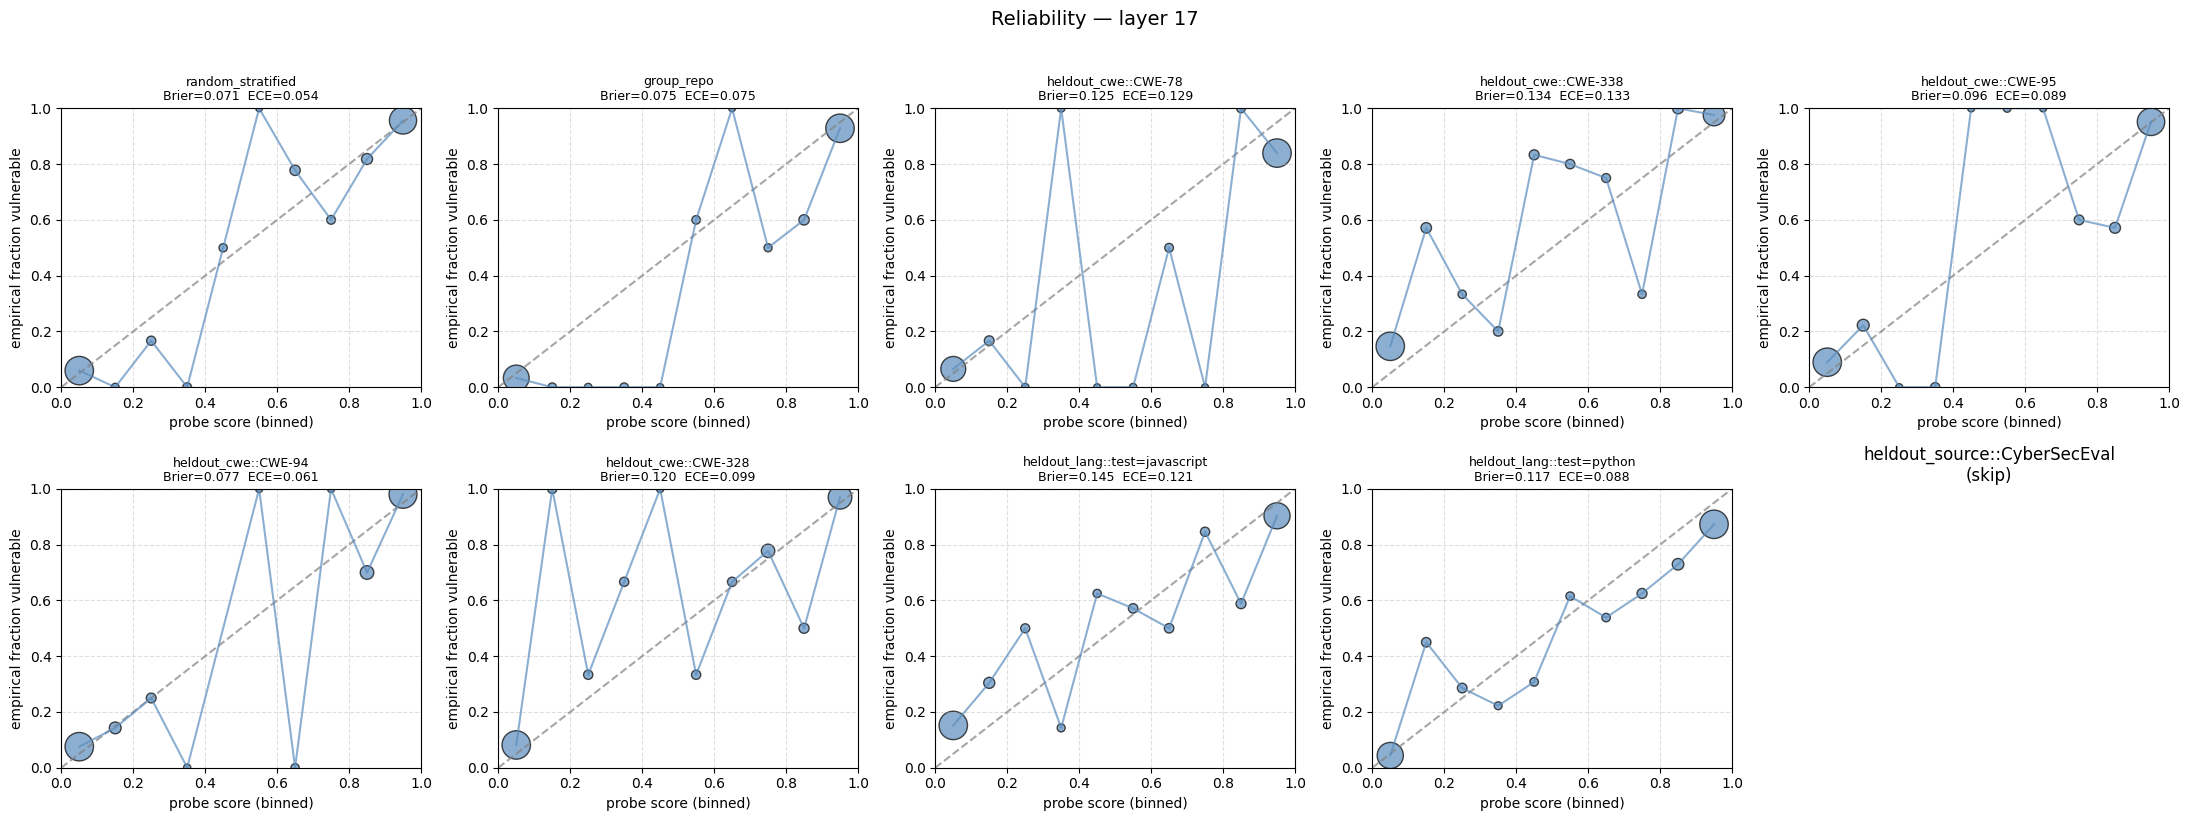

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8), squeeze=False)
for ax, sp in zip(axes.flat, splits):
    if len(np.unique(y[sp.train_idx])) < 2 or len(np.unique(y[sp.test_idx])) < 2:
        ax.set_title(f"{sp.name}\n(skip)")
        ax.axis("off")
        continue
    probe = fit_logreg_on_split(X, y, sp.train_idx)
    probs = probe.score(X[sp.test_idx])
    centers, acc, count = reliability_curve(y[sp.test_idx], probs, n_bins=10)
    cal = calibration_metrics(y[sp.test_idx], probs, n_bins=10)
    ax.plot([0, 1], [0, 1], "--", color="gray", alpha=0.7)
    valid = ~np.isnan(acc)
    sizes = count[valid] / max(count.max(), 1) * 400 + 20
    ax.scatter(centers[valid], acc[valid], s=sizes, alpha=0.7, color="#5b8dbe", edgecolors="black")
    ax.plot(centers[valid], acc[valid], color="#5b8dbe", alpha=0.7)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("probe score (binned)")
    ax.set_ylabel("empirical fraction vulnerable")
    ax.set_title(f"{sp.name}\nBrier={cal['brier']:.3f}  ECE={cal['ece']:.3f}", fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.4)
for ax in axes.flat[len(splits):]:
    ax.axis("off")
plt.suptitle(f"Reliability — layer {LAYER}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Threshold sweep (group_repo)

`group_repo` is the most representative deployment-like split: real
unseen code, but same dataset distribution. F1 there is the closest
proxy we have to "how the demo will behave in front of a stranger's
repo".

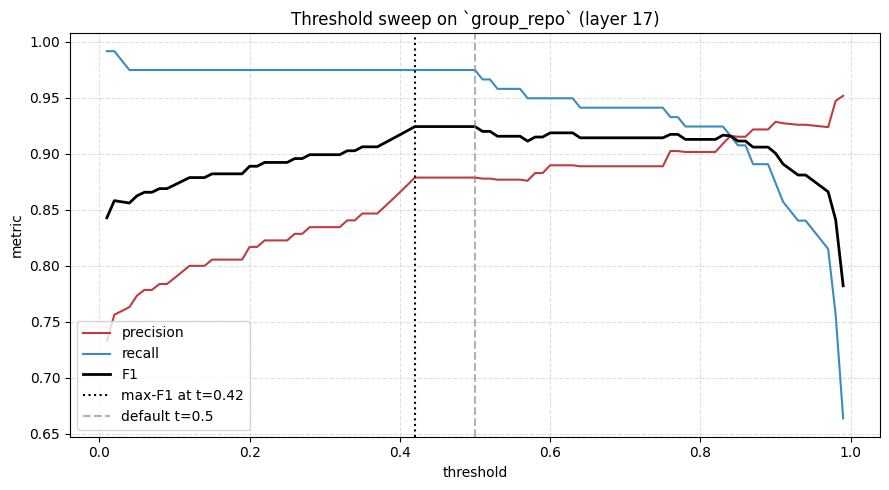

max-F1 = 0.924 at threshold = 0.420
   precision = 0.879   recall = 0.975

default threshold = 0.5:
   F1 = 0.924   precision = 0.879   recall = 0.975


In [3]:
sp = next(s for s in splits if s.name == "group_repo")
probe = fit_logreg_on_split(X, y, sp.train_idx)
probs = probe.score(X[sp.test_idx])
y_te = y[sp.test_idx]

thresholds = np.linspace(0.01, 0.99, 99)
recs = [recall_score(y_te, (probs >= t).astype(int), zero_division=0) for t in thresholds]
precs = [precision_score(y_te, (probs >= t).astype(int), zero_division=0) for t in thresholds]
f1s = [f1_score(y_te, (probs >= t).astype(int), zero_division=0) for t in thresholds]

best_idx = int(np.argmax(f1s))
best_thr = thresholds[best_idx]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, precs, label="precision", color="#bf3c3c")
ax.plot(thresholds, recs, label="recall", color="#3c8bbf")
ax.plot(thresholds, f1s, label="F1", color="black", linewidth=2)
ax.axvline(best_thr, color="black", linestyle=":", label=f"max-F1 at t={best_thr:.2f}")
ax.axvline(0.5, color="gray", linestyle="--", alpha=0.6, label="default t=0.5")
ax.set_xlabel("threshold")
ax.set_ylabel("metric")
ax.set_title(f"Threshold sweep on `group_repo` (layer {LAYER})")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

print(f"max-F1 = {f1s[best_idx]:.3f} at threshold = {best_thr:.3f}")
print(f"   precision = {precs[best_idx]:.3f}   recall = {recs[best_idx]:.3f}")
print()
print(f"default threshold = 0.5:")
default_idx = int(np.argmin(np.abs(thresholds - 0.5)))
print(f"   F1 = {f1s[default_idx]:.3f}   precision = {precs[default_idx]:.3f}   recall = {recs[default_idx]:.3f}")

## Suggestion

If `max-F1` threshold differs from 0.5 by more than 0.1, the streaming
UI should be updated to use the suggested threshold (and re-evaluated
qualitatively on `scripts/eval_probe.py`). If they're close, leave 0.5.

In [4]:
if abs(best_thr - 0.5) > 0.1:
    print(f"  RECOMMEND: update default threshold to {best_thr:.2f}")
else:
    print(f"  KEEP default threshold (0.5).")

  KEEP default threshold (0.5).
